honest review: Test set ko Day 67 mein Logistic Regression ke liye ek baar dekha tha. Us score ko dekh kar tumne model mein koi badlav nahi kiya, isliye test set abhi bhi saaf hai. Ab dono models ko usi test set par rakhenge, lekin decision CV se hoga, test se nahi. Test sirf confirm karta hai. Agar test result CV se ulta aaye, to wapas jaakar tuning mat karo. Bas result as-it-is likho.

1. Models aur data load karo:

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

X_train = pd.read_csv('../../data/processed/X_train.csv')
y_train = pd.read_csv('../../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../../data/processed/X_test.csv')
y_test = pd.read_csv('../../data/processed/y_test.csv').squeeze()

logreg = joblib.load('models/logreg_pipeline.joblib')     # Day 66 (scaler andar hai)
tree = joblib.load('models/decision_tree_tuned.joblib')   # Day 69 (raw features)

models = {'Logistic Regression': logreg, 'Decision Tree (tuned)': tree}

2. Round 1: CV par comparison (yeh decision wala round hai):

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # dono ke liye same folds
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results, cv_f1_folds = {}, {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=metrics)
    cv_results[name] = {k: r[f'test_{k}'].mean() for k in metrics}
    cv_results[name].update({f'{k}_std': r[f'test_{k}'].std() for k in ['f1']})
    cv_f1_folds[name] = r['test_f1']

cv_table = pd.DataFrame(cv_results).T.round(3)
print(cv_table)

                       accuracy  precision  recall     f1  roc_auc  f1_std
Logistic Regression       0.722      0.773   0.720  0.745    0.794   0.010
Decision Tree (tuned)     0.716      0.752   0.746  0.748    0.781   0.005


Same cv object dena zaroori hai, taaki dono models ko bilkul same folds mile. Tabhi comparison fair hai.

3. Fold-by-fold fark (kya fark real hai ya noise?):

In [3]:
folds = pd.DataFrame(cv_f1_folds).round(3)
folds['diff (Tree - LogReg)'] = (folds['Decision Tree (tuned)'] - folds['Logistic Regression']).round(3)
print(folds)
print("Tree beats LogReg in", (folds['diff (Tree - LogReg)'] > 0).sum(), "of 5 folds")

   Logistic Regression  Decision Tree (tuned)  diff (Tree - LogReg)
0                0.744                  0.740                -0.004
1                0.732                  0.749                 0.017
2                0.748                  0.749                 0.001
3                0.742                  0.754                 0.012
4                0.762                  0.749                -0.013
Tree beats LogReg in 3 of 5 folds


Agar ek model har fold mein jeet raha hai, to fark bharosemand hai. Agar fold-to-fold ulat-palat ho raha hai, to dono lagbhag barabar hain.

4. Round 2: Test set par final confirmation:

In [4]:
test_results, preds, probs = {}, {}, {}
for name, m in models.items():
    preds[name] = m.predict(X_test)
    probs[name] = m.predict_proba(X_test)[:, 1]
    test_results[name] = {
        'accuracy': accuracy_score(y_test, preds[name]),
        'precision': precision_score(y_test, preds[name]),
        'recall': recall_score(y_test, preds[name]),
        'f1': f1_score(y_test, preds[name]),
        'roc_auc': roc_auc_score(y_test, probs[name])
    }

test_table = pd.DataFrame(test_results).T.round(3)
print(test_table)

majority = y_test.value_counts(normalize=True).max()
print(f"\nNaive baseline accuracy: {majority:.3f}")

                       accuracy  precision  recall     f1  roc_auc
Logistic Regression       0.742      0.791   0.739  0.764    0.809
Decision Tree (tuned)     0.735      0.784   0.734  0.758    0.807

Naive baseline accuracy: 0.566


5. CV vs Test side-by-side (stability check):

In [5]:
compare = pd.DataFrame({
    'CV F1': cv_table['f1'],
    'Test F1': test_table['f1'],
})
compare['gap'] = (compare['Test F1'] - compare['CV F1']).round(3)
print(compare)

                       CV F1  Test F1    gap
Logistic Regression    0.745    0.764  0.019
Decision Tree (tuned)  0.748    0.758  0.010


Dono models ka gap chhota hona chahiye. Bada gap leakage ya overfitting ka signal hai.

6. Test score ki uncertainty (bootstrap):

In [6]:
rng = np.random.default_rng(42)
n = len(y_test)
y_arr = y_test.values
boot = {name: [] for name in models}
boot_diff = []

for _ in range(1000):
    idx = rng.integers(0, n, n)
    f = {name: f1_score(y_arr[idx], preds[name][idx]) for name in models}
    for name in models:
        boot[name].append(f[name])
    boot_diff.append(f['Decision Tree (tuned)'] - f['Logistic Regression'])

for name in models:
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    print(f"{name}: F1 = {test_table.loc[name, 'f1']:.3f}  (95% CI {lo:.3f} - {hi:.3f})")

lo, hi = np.percentile(boot_diff, [2.5, 97.5])
print(f"\nF1 difference (Tree - LogReg): 95% CI {lo:.3f} to {hi:.3f}")
print("Fark statistically clear hai" if (lo > 0 or hi < 0) else "Interval 0 ko cover karta hai: dono ko barabar maano")

Logistic Regression: F1 = 0.764  (95% CI 0.736 - 0.789)
Decision Tree (tuned): F1 = 0.758  (95% CI 0.731 - 0.786)

F1 difference (Tree - LogReg): 95% CI -0.026 to 0.015
Interval 0 ko cover karta hai: dono ko barabar maano


Test set mein sirf kuch sau customers hote hain, isliye ek akela F1 number pakka nahi hota. Bootstrap interval dikhata hai ki number kitna hil sakta hai. Agar fark ka interval 0 ko cross karta hai, to “ek jeeta” kehna jaldbaazi hogi.

7. Confusion matrix ka sneak peek (formal detail Day 71 mein):

In [7]:
for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Logistic Regression: TN=342, FP=117, FN=156, TP=442
Decision Tree (tuned): TN=338, FP=121, FN=159, TP=439


FN wo churners hain jo model se miss ho gaye. FP galat alarm hain.

8. ROC curve (formal detail Day 74 mein):

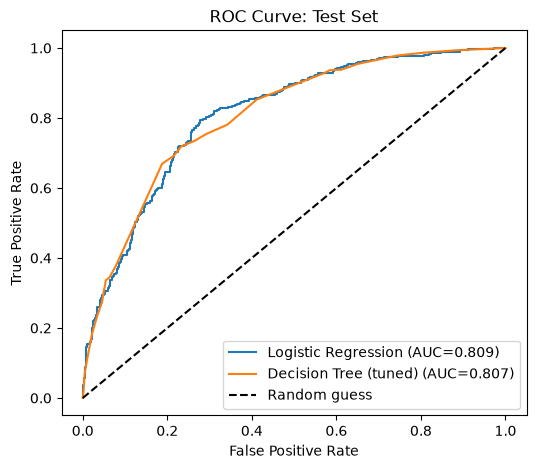

In [8]:
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={test_results[name]['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Test Set')
plt.legend()
plt.show()

Curve jitna upar-left ke paas, model utna behtar.

9. Dono models kaha agree/disagree karte hain:

In [9]:
agree = (preds['Logistic Regression'] == preds['Decision Tree (tuned)']).mean()
print(f"Dono ki predictions {agree:.1%} customers par same hain")

disagree = X_test[preds['Logistic Regression'] != preds['Decision Tree (tuned)']].copy()
disagree['actual'] = y_test[disagree.index]
disagree['LogReg_pred'] = preds['Logistic Regression'][disagree.index]
disagree['Tree_pred'] = preds['Decision Tree (tuned)'][disagree.index]
print(disagree.head(8))

Dono ki predictions 88.6% customers par same hain
    Recency  Frequency  Monetary_log  AvgOrderValue  Tenure  UniqueProducts  \
11       86          4      6.966307     264.825000     647              16   
17      290          2      5.790235     163.045000     290              74   
23      121          3      6.789850     295.926667     529              51   
25      182          2      7.044556     572.800000     182              17   
29      330          4      7.627393     513.172500     529              53   
31       22          1      4.282206      71.400000      22               1   
66      410         13      7.764708     181.151538     634             158   
68      299          3      7.308141     497.133333     382              58   

    Region_Rest of World  Region_UK  actual  LogReg_pred  Tree_pred  
11                 False       True       0            1          0  
17                 False       True       1            1          0  
23                 False    

10. Sirf score nahi, baaki dimensions bhi dekho:

In [10]:
print("""
                    Logistic Regression          Decision Tree
Interpretability    Coefficients (direction)     If-else rules (padhne mein aasan)
Scaling             Zaroori                      Nahi chahiye
Non-linear pattern  Nahi pakadta                 Pakad leta hai
Overfitting risk    Kam                          Zyada (tuning zaroori)
Probability         Smooth, well-behaved         Coarse (leaf-wise)
Stability           Data badalne par stable      Thoda hil sakta hai
""")


                    Logistic Regression          Decision Tree
Interpretability    Coefficients (direction)     If-else rules (padhne mein aasan)
Scaling             Zaroori                      Nahi chahiye
Non-linear pattern  Nahi pakadta                 Pakad leta hai
Overfitting risk    Kam                          Zyada (tuning zaroori)
Probability         Smooth, well-behaved         Coarse (leaf-wise)
Stability           Data badalne par stable      Thoda hil sakta hai



Agar dono ka score lagbhag same hai, to simple aur zyada stable model chuno.

11. Apna verdict markdown cell mein likho :

## Model Comparison (Logistic Regression vs Decision Tree)
- CV F1: LogReg [X] vs Tree [X] | Test F1: LogReg [X] vs Tree [X]
- Difference statistically clear? [Haan/Nahi, bootstrap CI ke hisaab se]
- Recall (churners pakadne ki taakat): [X] vs [X]
- Chosen baseline: [model] kyunki [apna reason: recall / stability / interpretability]
- Note: Day 83-85 mein Random Forest aur XGBoost in dono ko beat karne ki koshish karenge.

12. result save

In [12]:
cv_table.to_csv('../../reports/cv_comparison_day70.csv')
test_table.to_csv('../../reports/test_comparison_day70.csv')